# Test matrices generated by the PEG algorithm

In [2]:
from coder.Coder import Coder
from decoder.Decoder import Decoder
from PEG.PEG import PEG
from PEG.PEG_fast import PEG_fast
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor

In [7]:
PEG(1000, 1500, 5).peg()

In [3]:
PEG_fast(1000, 1500, 5).peg()

In [ ]:
def bitflipping(path):
    H = np.loadtxt(path, delimiter=',', dtype=np.int8)
    c = Coder.get_message(H)
    k = 40
    repeat = 50
    deep = 100
    p = np.linspace(0, 0.15, k)
    p_decode = Decoder.bitflipping_decoding_for_many(H, c, p, repeat, deep)
    return p, p_decode, path

In [ ]:
l_list = list(range(5, 9)) + [20]

with ThreadPoolExecutor() as executor:
    results = list(executor.map(bitflipping, [f'data/H_matrix/H{l}_1000x1500.txt' for l in l_list]))


In [ ]:
for p, p_decode, path in results:
    plt.plot(p, p_decode, label=f'${path}$')
plt.legend()
plt.ylabel('Вероятность ошибки декодирования')
plt.xlabel('Вероятность ошибки в канале')
# plt.yscale('log')
plt.grid()
plt.tight_layout()
plt.savefig('data/H.pdf')
plt.show()

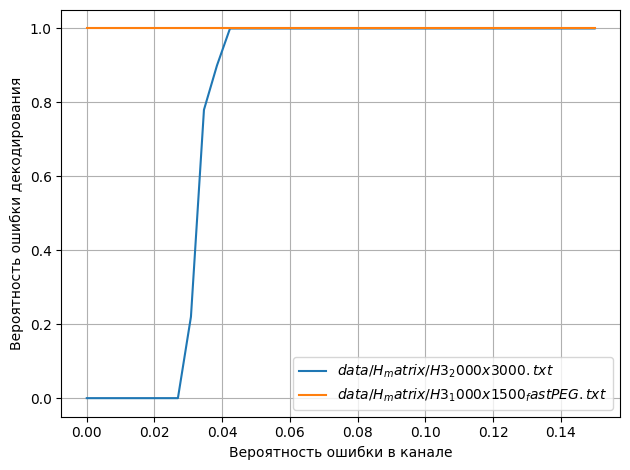

In [54]:
p, p_decode, path = bitflipping('data/H_matrix/H3_2000x3000.txt')
plt.plot(p, p_decode, label=f'${path}$')
p, p_decode, path = bitflipping('data/H_matrix/H3_1000x1500_fastPEG.txt')
plt.plot(p, p_decode, label=f'${path}$')
plt.legend()
plt.ylabel('Вероятность ошибки декодирования')
plt.xlabel('Вероятность ошибки в канале')
# plt.yscale('log')
plt.grid()
plt.tight_layout()
plt.savefig('data/H.pdf')
plt.show()